# ДЗ: чанкинг, метаданные, ChromaDB, LlamaIndex, Ollama и полный RAG-пайплайн
Корпус — твой `report.docx` (отчёт по практике): в нём есть заголовки, короткие реквизиты и длинные абзацы по 600–1000 символов, то есть есть что дробить.

Шаги: **1** python-docx → **2** чанкинг (свой fixed-size, LlamaIndex, по абзацам, гибрид) → **3** метаданные → **4** ChromaDB (сервер, поиск, фильтры, оценка релевантности, разные эмбеддинги, параметры чанкинга) → **5** Ollama + LlamaIndex → **6** полный пайплайн.

> Запуск ChromaDB в Docker: `docker run -d --name chroma -p 8000:8000 -v $(pwd)/chroma-data:/data chromadb/chroma`. Ноутбук подключается к `localhost:8000` через `HttpClient`.

In [19]:
import os, re, hashlib, zipfile, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from docx import Document
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 80)

DOCX_PATH   = os.environ.get("DOCX_PATH", "report.docx")
CHROMA_HOST = os.environ.get("CHROMA_HOST", "localhost")
CHROMA_PORT = int(os.environ.get("CHROMA_PORT", 8000))
OLLAMA_URL  = os.environ.get("OLLAMA_URL", "http://localhost:11434")
print("Документ:", DOCX_PATH)

Документ: report.docx


## 1. python-docx: абзацы, первые слова, таблицы

In [20]:
doc = Document(DOCX_PATH)
print("Всего абзацев в файле:", len(doc.paragraphs), "| таблиц:", len(doc.tables))
paras = []                                   # непустые абзацы: (номер абзаца в файле, стиль, текст)
for i, p in enumerate(doc.paragraphs):
    if p.text.strip():
        paras.append({"idx_in_docx": i, "style": p.style.name, "text": p.text.replace("\xa0", " ").strip()})
print("Непустых абзацев:", len(paras))

for n, p in enumerate(paras[:12]):
    first = " ".join(p["text"].split()[:3])
    print(f"#{n:<3} (абзац {p['idx_in_docx']:<3} стиль {p['style']!r:<16}) первые слова: {first}")

Всего абзацев в файле: 185 | таблиц: 0
Непустых абзацев: 83
#0   (абзац 0   стиль 'Normal'        ) первые слова: Министерство образования Республики
#1   (абзац 1   стиль 'Normal'        ) первые слова: Учреждение образования
#2   (абзац 2   стиль 'Normal'        ) первые слова: Белорусский государственный университет
#3   (абзац 3   стиль 'Normal'        ) первые слова: информатики и радиоэлектроники
#4   (абзац 6   стиль 'Normal'        ) первые слова: Факультет компьютерного проектирования
#5   (абзац 8   стиль 'Normal'        ) первые слова: Кафедра инженерной психологии
#6   (абзац 10  стиль 'Normal'        ) первые слова: Специальность: 6-05-0612-01 Программная
#7   (абзац 16  стиль 'Normal'        ) первые слова: ОТЧЕТ ПО УЧЕБНОЙ
#8   (абзац 23  стиль 'Normal'        ) первые слова: Студент группы 510902
#9   (абзац 25  стиль 'Normal'        ) первые слова: Руководитель практики
#10  (абзац 26  стиль 'Normal'        ) первые слова: старший преподаватель кафедры
#11  (абзац 37  

In [21]:
# Сопоставление с оригиналом: считаем <w:p> и <w:tbl> прямо в XML документа
with zipfile.ZipFile(DOCX_PATH) as z:
    xml = z.read("word/document.xml").decode("utf8")
body_paras = len(re.findall(r"<w:p[ >]", xml))
print("абзацев в XML (<w:p>):", body_paras, "| python-docx .paragraphs:", len(doc.paragraphs), "| таблиц в XML:", len(re.findall(r"<w:tbl>", xml)))
# в XML <w:p> считаются и абзацы внутри таблиц/надписей, поэтому при отсутствии таблиц числа должны совпасть
print("Совпадает с оригиналом" if body_paras == len(doc.paragraphs) else "Различие: абзацы внутри таблиц или надписей")
print("\nСтили в документе:", pd.Series([p["style"] for p in paras]).value_counts().to_dict())

абзацев в XML (<w:p>): 185 | python-docx .paragraphs: 185 | таблиц в XML: 0
Совпадает с оригиналом

Стили в документе: {'Normal': 71, 'List Paragraph': 12}


In [22]:
# В отчёте таблиц нет, поэтому показываем работу с таблицами на небольшом документе, собранном в памяти
demo = Document()
t = demo.add_table(rows=3, cols=3); t.style = "Table Grid"
for r, row in enumerate([["Метод", "Выборка", "Время"], ["Юзабилити-тест", "5-8", "60 мин"], ["Кликстрим", "тысячи", "—"]]):
    for c, val in enumerate(row):
        t.cell(r, c).text = val
demo.save("demo_table.docx")
d2 = Document("demo_table.docx")
for ti, tb in enumerate(d2.tables):
    print(f"Таблица {ti}: {len(tb.rows)} строк x {len(tb.columns)} столбцов")
    for row in tb.rows:
        print("  |", " | ".join(cell.text for cell in row.cells))
# Важно: doc.paragraphs НЕ содержит текста из таблиц, его нужно читать отдельно через doc.tables

Таблица 0: 3 строк x 3 столбцов
  | Метод | Выборка | Время
  | Юзабилити-тест | 5-8 | 60 мин
  | Кликстрим | тысячи | —


## 2. Чанкинг
### 2.1. Fixed-size чанкинг без библиотек
Режем по символам, не разрывая слова, с перекрытием `overlap`. Для каждого чанка сохраняем границы `start/end` в исходном тексте — они понадобятся для метаданных и оценки качества.

Что исправлено по сравнению с исходным ноутбуком: при поиске границы слова `text.find(' ', start, end)` мог вернуть `-1`, и тогда `start` становился отрицательным и чанкинг зацикливался или перескакивал в конец текста; чанки начинались с середины слов («программирования, где разработчик должен» повторялось в двух чанках).

In [23]:
def fixed_size_chunks(text, size=500, overlap=50):
    """Нарезка на чанки длиной <= size символов с перекрытием overlap, границы подгоняются под пробел."""
    assert 0 <= overlap < size
    chunks, start, n = [], 0, len(text)
    while start < n:
        end = min(start + size, n)
        if end < n:                                            # не режем слово пополам
            ws = max(text.rfind(" ", start, end), text.rfind("\n", start, end))
            if ws > start + overlap:                           # гарантирует продвижение вперёд
                end = ws
        piece = text[start:end]
        if piece.strip():
            chunks.append({"text": piece.strip(), "start": start, "end": end})
        if end >= n:
            break
        nxt = end - overlap
        sp = text.find(" ", nxt, end)                          # новый чанк начинаем с целого слова
        start = sp + 1 if sp != -1 else end
    return chunks

# Тесты
sample = " ".join(f"слово{i}" for i in range(400))
for size, ov in [(100, 0), (100, 20), (333, 50)]:
    ch = fixed_size_chunks(sample, size, ov)
    assert all(len(c["text"]) <= size for c in ch), "чанк длиннее size"
    assert ch[0]["start"] == 0 and ch[-1]["end"] == len(sample), "не покрыт весь текст"
    assert all(a["end"] > b["start"] or ov == 0 for a, b in zip(ch, ch[1:])), "нет перекрытия"
    assert all(" ".join(c["text"].split()) == c["text"] and not c["text"].startswith("лово") for c in ch), "слово разрезано"
    print(f"size={size:<4} overlap={ov:<3} -> {len(ch)} чанков, средняя длина {np.mean([len(c['text']) for c in ch]):.0f}")
print("\nПример перекрытия:")
ch = fixed_size_chunks(sample, 100, 20)
print(" 1:", ch[0]["text"]); print(" 2:", ch[1]["text"])

size=100  overlap=0   -> 36 чанков, средняя длина 96
size=100  overlap=20  -> 43 чанков, средняя длина 97
size=333  overlap=50  -> 13 чанков, средняя длина 309

Пример перекрытия:
 1: слово0 слово1 слово2 слово3 слово4 слово5 слово6 слово7 слово8 слово9 слово10 слово11 слово12
 2: слово11 слово12 слово13 слово14 слово15 слово16 слово17 слово18 слово19 слово20 слово21 слово22


In [24]:
full_text = "\n\n".join(p["text"] for p in paras)
# смещения абзацев в склеенном тексте: нужны, чтобы по границам чанка узнать, каким абзацам он принадлежит
offs, pos = [], 0
for p in paras:
    offs.append((pos, pos + len(p["text"]))); pos += len(p["text"]) + 2

def paras_of_span(s, e):
    ids = [i for i, (a, b) in enumerate(offs) if a < e and b > s]
    return (ids[0], ids[-1]) if ids else (0, 0)

for size in (200, 500, 1000):
    ch = fixed_size_chunks(full_text, size, int(size * 0.1))
    print(f"fixed size={size:<5} -> {len(ch):>3} чанков")
print("\nДлины абзацев (символы): min", min(len(p['text']) for p in paras), "медиана", int(np.median([len(p['text']) for p in paras])), "max", max(len(p['text']) for p in paras))

fixed size=200   ->  85 чанков
fixed size=500   ->  34 чанков
fixed size=1000  ->  17 чанков

Длины абзацев (символы): min 8 медиана 77 max 1023


### 2.2. Что умеет LlamaIndex в области чанкинга
`SentenceSplitter` (по предложениям, с лимитом токенов), `TokenTextSplitter` (по токенам), `SemanticSplitterNodeParser` (по смыслу, через эмбеддинги), `MarkdownNodeParser`/`HierarchicalNodeParser` (по структуре) и готовые ридеры файлов (`DocxReader` / `SimpleDirectoryReader`). Сравним два основных сплиттера на нашем тексте.

In [25]:
from llama_index.core.node_parser import SentenceSplitter, TokenTextSplitter
from llama_index.core import Document as LDoc

ld = LDoc(text=full_text)
rows = []
for name, sp in [("SentenceSplitter(128/16)", SentenceSplitter(chunk_size=128, chunk_overlap=16)),
                 ("SentenceSplitter(256/32)", SentenceSplitter(chunk_size=256, chunk_overlap=32)),
                 ("TokenTextSplitter(128/16)", TokenTextSplitter(chunk_size=128, chunk_overlap=16)),
                 ("TokenTextSplitter(256/32)", TokenTextSplitter(chunk_size=256, chunk_overlap=32))]:
    nodes = sp.get_nodes_from_documents([ld])
    L = [len(n.get_content()) for n in nodes]
    cut = sum(1 for n in nodes if n.get_content()[-1] not in ".!?»…:;)" )
    rows.append({"сплиттер": name, "чанков": len(nodes), "ср. символов": int(np.mean(L)), "макс": max(L), "заканчивается не на знаке препинания": cut})
pd.DataFrame(rows).set_index("сплиттер")

,чанков,ср. символов,макс,заканчивается не на знаке препинания
сплиттер,,,,
SentenceSplitter(128/16),69,224,314,4
SentenceSplitter(256/32),33,475,579,0
TokenTextSplitter(128/16),62,278,331,57
TokenTextSplitter(256/32),31,559,652,27


In [26]:
# Почему «токены» в LlamaIndex по умолчанию плохо подходят для русского: токенизатор tiktoken (GPT) даёт много токенов на слово
import tiktoken
enc = tiktoken.get_encoding("cl100k_base")
ru = full_text[:2000]; en = "Machine learning is a branch of artificial intelligence in which computer systems learn to perform tasks without being explicitly programmed " * 3
print(f"русский текст: {len(ru)} символов -> {len(enc.encode(ru))} токенов (~{len(ru)/len(enc.encode(ru)):.1f} симв/токен)")
print(f"английский   : {len(en)} символов -> {len(enc.encode(en))} токенов (~{len(en)/len(enc.encode(en)):.1f} симв/токен)")
print("Поэтому chunk_size=200 токенов — это ~", int(200 * len(ru) / len(enc.encode(ru))), "русских символов, а границы часто попадают внутрь слов.")

русский текст: 2000 символов -> 906 токенов (~2.2 симв/токен)
английский   : 423 символов -> 61 токенов (~6.9 симв/токен)
Поэтому chunk_size=200 токенов — это ~ 441 русских символов, а границы часто попадают внутрь слов.


### 2.3. Чанкинг по абзацам (чтение .docx как стратегия чанкинга) и гибрид
* **По абзацам:** один абзац = один чанк. Границы смысловые, но размер непредсказуем: заголовок из 10 символов и абзац из 1000.
* **Гибрид (по заданию):** абзацы остаются целыми, а **большие абзацы (> `max_chars`) дробятся fixed-size чанкингом**. Короткие абзацы (< `min_chars`, например заголовки и реквизиты) приклеиваются к следующему, чтобы заголовок не жил отдельным бесполезным чанком.

In [27]:
def is_heading(p):
    t = p["text"]
    return p["style"].lower().startswith(("heading", "заголовок")) or bool(re.match(r"^\d+\s+[А-ЯЁ«A-Z]{3}", t)) and len(t) < 120

def paragraph_chunks(paras):
    return [dict(text=p["text"], para_start=i, para_end=i, chunk_type="paragraph") for i, p in enumerate(paras)]

def hybrid_chunks(paras, max_chars=500, overlap=50, min_chars=0):
    """Абзацы целиком; абзац > max_chars режется fixed-size; абзацы короче min_chars склеиваются со следующим."""
    out, buf, buf_start = [], [], None
    for i, p in enumerate(paras):
        t = p["text"]
        if len(t) < min_chars:                                  # короткий: копим
            buf.append(t); buf_start = i if buf_start is None else buf_start
            continue
        if buf:                                                 # приклеиваем накопленное к текущему абзацу
            t = " ".join(buf + [t]); s = buf_start; buf, buf_start = [], None
        else:
            s = i
        if len(t) > max_chars:
            for c in fixed_size_chunks(t, max_chars, overlap):
                out.append(dict(text=c["text"], para_start=s, para_end=i, chunk_type="split_paragraph"))
        else:
            out.append(dict(text=t, para_start=s, para_end=i, chunk_type="full_paragraph" if s == i else "merged_paragraphs"))
    if buf:
        out.append(dict(text=" ".join(buf), para_start=buf_start, para_end=len(paras) - 1, chunk_type="merged_paragraphs"))
    return out

def fixed_chunks(paras_, size, overlap):
    ft = "\n\n".join(p["text"] for p in paras_)
    o, pos = [], 0
    for p in paras_:
        o.append((pos, pos + len(p["text"]))); pos += len(p["text"]) + 2
    res = []
    for c in fixed_size_chunks(ft, size, overlap):
        ids = [i for i, (a, b) in enumerate(o) if a < c["end"] and b > c["start"]]
        res.append(dict(text=c["text"], para_start=ids[0], para_end=ids[-1], chunk_type="fixed"))
    return res

for name, ch in [("по абзацам", paragraph_chunks(paras)), ("гибрид max=500", hybrid_chunks(paras, 500, 50, 60)),
                 ("fixed 500", fixed_chunks(paras, 500, 50))]:
    L = [len(c["text"]) for c in ch]
    print(f"{name:<16}: чанков {len(ch):>3}, символов min/медиана/max = {min(L)}/{int(np.median(L))}/{max(L)}, типы: {pd.Series([c['chunk_type'] for c in ch]).value_counts().to_dict()}")

по абзацам      : чанков  83, символов min/медиана/max = 8/77/1023, типы: {'paragraph': 83}
гибрид max=500  : чанков  55, символов min/медиана/max = 67/285/499, типы: {'full_paragraph': 28, 'split_paragraph': 18, 'merged_paragraphs': 9}
fixed 500       : чанков  34, символов min/медиана/max = 412/495/499, типы: {'fixed': 34}


## 3. Метаданные
Каждый чанк получает **обязательные** `doc_id`, `chunk_index` и дополнительно: `chunk_id`, `source`, `chunk_type`, `para_start/para_end` (какие абзацы покрывает), `section` (ближайший заголовок выше), `n_chars`.

Chroma принимает в метаданных только `str/int/float/bool`, поэтому списки хранить нельзя — диапазон абзацев записан двумя числами.

In [28]:
def add_metadata(chunks, paras, doc_path):
    doc_id = hashlib.md5(os.path.basename(doc_path).encode()).hexdigest()[:8]
    # ближайший заголовок для каждого абзаца
    section, sec_of = "Без раздела", []
    for p in paras:
        if is_heading(p): section = p["text"][:80]
        sec_of.append(section)
    out = []
    for i, c in enumerate(chunks):
        md_ = dict(doc_id=doc_id, chunk_index=i, chunk_id=f"{doc_id}_{i:04d}", source=os.path.basename(doc_path),
                   chunk_type=c["chunk_type"], para_start=c["para_start"], para_end=c["para_end"],
                   section=sec_of[c["para_start"]], n_chars=len(c["text"]))
        out.append({**c, "metadata": md_})
    return out

chunks_demo = add_metadata(hybrid_chunks(paras, 500, 50, 60), paras, DOCX_PATH)
meta_df = pd.DataFrame([{**c["metadata"], "начало текста": c["text"][:50]} for c in chunks_demo])
assert meta_df[["doc_id", "chunk_index"]].notna().all().all() and meta_df["chunk_id"].is_unique
print("Обязательные поля doc_id и chunk_index заполнены у всех", len(meta_df), "чанков, chunk_id уникален")
meta_df.head(12)

Обязательные поля doc_id и chunk_index заполнены у всех 55 чанков, chunk_id уникален


,doc_id,chunk_index,chunk_id,source,chunk_type,para_start,para_end,section,n_chars,начало текста
0,a42ed8e7,0,a42ed8e7_0000,report.docx,merged_paragraphs,0,8,Без раздела,378,Министерство образования Республики Беларусь Учреж
1,a42ed8e7,1,a42ed8e7_0001,report.docx,merged_paragraphs,9,13,Без раздела,186,Руководитель практики старший преподаватель кафедр
2,a42ed8e7,2,a42ed8e7_0002,report.docx,merged_paragraphs,14,15,Без раздела,169,Обзор компании ООО «Гейм Стрим»………………………………...4 Об
3,a42ed8e7,3,a42ed8e7_0003,report.docx,full_paragraph,16,16,Без раздела,116,Разработка карты эмпатии для веб-ресурса (мобильно
4,a42ed8e7,4,a42ed8e7_0004,report.docx,full_paragraph,17,17,Без раздела,117,Возможные пути решения проблем веб-ресурса (мобиль
5,a42ed8e7,5,a42ed8e7_0005,report.docx,merged_paragraphs,18,20,Без раздела,172,Заключение……………………………………………………………………….16 Список ис
6,a42ed8e7,6,a42ed8e7_0006,report.docx,merged_paragraphs,21,22,1 ИНДИВИДУАЛЬНОЕ ЗАДАНИЕ УЧЕБНОЙ (ОЗНАКОМИТЕЛЬНОЙ) ПРАКТИКИ,162,1 ИНДИВИДУАЛЬНОЕ ЗАДАНИЕ УЧЕБНОЙ (ОЗНАКОМИТЕЛЬНОЙ)
7,a42ed8e7,7,a42ed8e7_0007,report.docx,merged_paragraphs,23,32,1 ИНДИВИДУАЛЬНОЕ ЗАДАНИЕ УЧЕБНОЙ (ОЗНАКОМИТЕЛЬНОЙ) ПРАКТИКИ,298,Содержание задания: Полное наименование компаний Ю
8,a42ed8e7,8,a42ed8e7_0008,report.docx,full_paragraph,33,33,1 ИНДИВИДУАЛЬНОЕ ЗАДАНИЕ УЧЕБНОЙ (ОЗНАКОМИТЕЛЬНОЙ) ПРАКТИКИ,331,Провести исследование и составить карту эмпатии ве
9,a42ed8e7,9,a42ed8e7_0009,report.docx,merged_paragraphs,34,35,2 ОБЗОР КОМПАНИИ ООО «Гейм Стрим»,145,2 ОБЗОР КОМПАНИИ ООО «Гейм Стрим» Полное наименова


## 4. ChromaDB
### 4.1. Подключение к серверу и проверка работоспособности

In [29]:
import chromadb
client = chromadb.HttpClient(host=CHROMA_HOST, port=CHROMA_PORT)
print("heartbeat:", client.heartbeat(), "| версия клиента chromadb:", chromadb.__version__)
col = client.get_or_create_collection("sanity_check")
col.add(ids=["a", "b"], embeddings=[[1.0, 0.0], [0.0, 1.0]], documents=["кошка пьёт молоко", "рубль укрепился"], metadatas=[{"t": "x"}, {"t": "y"}])
print("запись/поиск работают:", col.query(query_embeddings=[[0.9, 0.1]], n_results=1)["documents"][0], "| count =", col.count())
client.delete_collection("sanity_check")

heartbeat: 1793824145802923964 | версия клиента chromadb: 1.5.9
запись/поиск работают: ['кошка пьёт молоко'] | count = 2


### 4.2. Эталонные вопросы для оценки релевантности

In [30]:
# gold = номера абзацев (в списке paras), в которых содержится ответ; kw = ключевое слово, которое должно быть в ответе
QA = [
 ("В каком году компания Game Stream получила статус резидента Парка высоких технологий?", {41}, "2008"),
 ("Какой юридический адрес у ООО «Гейм Стрим»?", {36}, "Партизанский"),
 ("Какой технологический стек используется в компании?", {50}, "Kubernetes"),
 ("Какие ограничения у лабораторного юзабилити-тестирования?", {69}, "выборка"),
 ("Из каких этапов состоит лабораторное тестирование?", {59}, "сценари"),
 ("Какой пример юзабилити-теста связан с интернет-банком?", {61}, "получател"),
 ("Какие боли испытывают покупатели 5element.by?", {81}, "доставк"),
 ("Кто является центральным персонажем карты эмпатии?", {73}, "Будько"),
 ("Что покупатели говорят о сайте 5element?", {77}, "подтормаживает"),
 ("Что покупатели слышат от друзей и коллег?", {79}, "Onliner"),
 ("Какие данные фиксируются во время юзабилити-тестирования?", {57}, "время выполнения"),
 ("Чем занимается команда Blitz-проектов?", {46}, "мобильн"),
 ("Какая цель исследования пользовательского опыта на сайте 5element?", {72}, "конверсию"),
 ("Какие преимущества у лабораторного юзабилити-тестирования?", {67}, "мотивацию"),
 ("Какие направления деятельности есть у компании?", set(range(43, 50)), "World of Tanks"),
]
OOS = "Дай мне рецепт пиццы Маргарита"          # вопроса нет в документе: корректная система должна отказаться
# проверка эталона: ключевое слово реально есть в абзацах gold
for q, gold, kw in QA:
    assert any(kw.lower() in paras[g]["text"].lower() for g in gold), (q, kw)
print("Вопросов:", len(QA), "+ 1 вне документа. Эталон проверен: ключевые слова найдены в нужных абзацах.")

Вопросов: 15 + 1 вне документа. Эталон проверен: ключевые слова найдены в нужных абзацах.


### 4.3. Эмбеддинг-модели и функция оценки
Сравниваем три модели: `paraphrase-multilingual-MiniLM-L12-v2` (как в твоём ноутбуке), `intfloat/multilingual-e5-small` (модель именно для поиска; требует префиксы `query:`/`passage:`) и `cointegrated/rubert-tiny2` (компактная русская).

Метрики: `hit@k` — среди первых k найденных чанков есть чанк, пересекающийся с абзацем-ответом; `MRR` — средняя величина 1/ранг первого правильного чанка.

In [31]:
from sentence_transformers import SentenceTransformer
EMB = {
    "MiniLM-multilingual": dict(name="paraphrase-multilingual-MiniLM-L12-v2", q="", p=""),
    "multilingual-e5-small": dict(name="intfloat/multilingual-e5-small", q="query: ", p="passage: "),
    "rubert-tiny2": dict(name="cointegrated/rubert-tiny2", q="", p=""),
}
models = {}
for k, v in EMB.items():
    t = time.time(); models[k] = SentenceTransformer(v["name"]); print(f"{k:<22} загружена за {time.time()-t:.0f} с, dim={models[k].get_sentence_embedding_dimension()}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

/var/folders/vh/ct099spj1gx7k1z__sx2wtkc0000gn/T/ipykernel_25132/3756975144.py:9: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  t = time.time(); models[k] = SentenceTransformer(v["name"]); print(f"{k:<22} загружена за {time.time()-t:.0f} с, dim={models[k].get_sentence_embedding_dimension()}")


MiniLM-multilingual    загружена за 5 с, dim=384


model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (20 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

rubert-tiny2           загружена за 11 с, dim=312


/var/folders/vh/ct099spj1gx7k1z__sx2wtkc0000gn/T/ipykernel_25132/3756975144.py:9: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  t = time.time(); models[k] = SentenceTransformer(v["name"]); print(f"{k:<22} загружена за {time.time()-t:.0f} с, dim={models[k].get_sentence_embedding_dimension()}")


In [32]:
_n = [0]
def build_collection(chunks, emb_key, tag):
    m, cfg = models[emb_key], EMB[emb_key]
    name = f"ev-{tag}-{emb_key}".replace("_", "-")[:60]
    try: client.delete_collection(name)                 # пересоздаём, чтобы чанки не дублировались при повторном запуске
    except Exception: pass
    col = client.create_collection(name, metadata={"hnsw:space": "cosine"})
    vecs = m.encode([cfg["p"] + c["text"] for c in chunks], normalize_embeddings=True, batch_size=32)
    col.add(ids=[c["metadata"]["chunk_id"] for c in chunks], embeddings=vecs.tolist(),
            documents=[c["text"] for c in chunks], metadatas=[c["metadata"] for c in chunks])
    return col

def retrieve(col, emb_key, question, k=5, where=None):
    qv = models[emb_key].encode(EMB[emb_key]["q"] + question, normalize_embeddings=True)
    return col.query(query_embeddings=[qv.tolist()], n_results=k, where=where, include=["documents", "metadatas", "distances"])

def evaluate(chunks, emb_key, tag, k=5):
    col = build_collection(chunks, emb_key, tag)
    ranks, rel_scores = [], []
    for q, gold, kw in QA:
        r = retrieve(col, emb_key, q, k)
        hit = [bool(set(range(m["para_start"], m["para_end"] + 1)) & gold) for m in r["metadatas"][0]]
        ranks.append(hit.index(True) + 1 if any(hit) else np.inf)
        rel_scores.append(1 - r["distances"][0][0])
    ranks = np.array(ranks)
    oos = 1 - retrieve(col, emb_key, OOS, 1)["distances"][0][0]
    return dict(chunks=len(chunks), avg_chars=int(np.mean([len(c["text"]) for c in chunks])),
                hit1=(ranks == 1).mean(), hit3=(ranks <= 3).mean(), hit5=(ranks <= 5).mean(),
                MRR=(1 / ranks).mean(), top1_sim_in=float(np.mean(rel_scores)), top1_sim_oos=float(oos))

In [33]:
CONFIGS = {
    "fixed-200":      lambda: add_metadata(fixed_chunks(paras, 200, 20), paras, DOCX_PATH),
    "fixed-500":      lambda: add_metadata(fixed_chunks(paras, 500, 50), paras, DOCX_PATH),
    "fixed-1000":     lambda: add_metadata(fixed_chunks(paras, 1000, 100), paras, DOCX_PATH),
    "paragraph":      lambda: add_metadata(paragraph_chunks(paras), paras, DOCX_PATH),
    "hybrid-300":     lambda: add_metadata(hybrid_chunks(paras, 300, 30, 60), paras, DOCX_PATH),
    "hybrid-500":     lambda: add_metadata(hybrid_chunks(paras, 500, 50, 60), paras, DOCX_PATH),
}
rows, t0 = [], time.time()
for cname, mk_ in CONFIGS.items():
    chunks = mk_()
    for ek in EMB:
        rows.append({"чанкинг": cname, "эмбеддинг": ek, **evaluate(chunks, ek, cname)})
    print(cname, "готово", round(time.time() - t0), "с")
grid = pd.DataFrame(rows)
grid.round(3)

fixed-200 готово 5 с
fixed-500 готово 7 с
fixed-1000 готово 8 с
paragraph готово 9 с
hybrid-300 готово 11 с
hybrid-500 готово 12 с


,чанкинг,эмбеддинг,chunks,avg_chars,hit1,hit3,hit5,MRR,top1_sim_in,top1_sim_oos
0,fixed-200,MiniLM-multilingual,85,193,0.533,0.667,0.800,0.611,0.641,0.182
1,fixed-200,multilingual-e5-small,85,193,0.733,0.800,0.867,0.772,0.878,0.806
2,fixed-200,rubert-tiny2,85,193,0.400,0.600,0.667,0.502,0.654,0.503
3,fixed-500,MiniLM-multilingual,34,492,0.400,0.867,0.933,0.639,0.560,0.145
4,fixed-500,multilingual-e5-small,34,492,0.533,0.800,0.933,0.686,0.871,0.802
5,fixed-500,rubert-tiny2,34,492,0.400,0.467,0.600,0.452,0.609,0.453
6,fixed-1000,MiniLM-multilingual,17,986,0.533,0.867,1.000,0.711,0.547,0.087
7,fixed-1000,multilingual-e5-small,17,986,0.600,0.800,1.000,0.743,0.868,0.812
8,fixed-1000,rubert-tiny2,17,986,0.333,0.533,0.600,0.424,0.597,0.436
9,paragraph,MiniLM-multilingual,83,182,0.533,0.867,0.867,0.667,0.683,0.287


In [34]:
print("MRR (чем выше, тем лучше):")
piv = grid.pivot(index="чанкинг", columns="эмбеддинг", values="MRR").loc[list(CONFIGS)]
display(piv.round(3))
print("hit@1:"); display(grid.pivot(index="чанкинг", columns="эмбеддинг", values="hit1").loc[list(CONFIGS)].round(3))
print("Число чанков и средняя длина:"); display(grid[grid["эмбеддинг"] == "MiniLM-multilingual"].set_index("чанкинг")[["chunks", "avg_chars"]].loc[list(CONFIGS)])

MRR (чем выше, тем лучше):


эмбеддинг,MiniLM-multilingual,multilingual-e5-small,rubert-tiny2
чанкинг,,,
fixed-200,0.611,0.772,0.502
fixed-500,0.639,0.686,0.452
fixed-1000,0.711,0.743,0.424
paragraph,0.667,0.656,0.219
hybrid-300,0.802,0.722,0.513
hybrid-500,0.761,0.722,0.436


hit@1:


эмбеддинг,MiniLM-multilingual,multilingual-e5-small,rubert-tiny2
чанкинг,,,
fixed-200,0.533,0.733,0.400
fixed-500,0.400,0.533,0.400
fixed-1000,0.533,0.600,0.333
paragraph,0.533,0.600,0.067
hybrid-300,0.733,0.667,0.400
hybrid-500,0.667,0.667,0.200


Число чанков и средняя длина:


,chunks,avg_chars
чанкинг,,
fixed-200,85,193
fixed-500,34,492
fixed-1000,17,986
paragraph,83,182
hybrid-300,74,214
hybrid-500,55,283


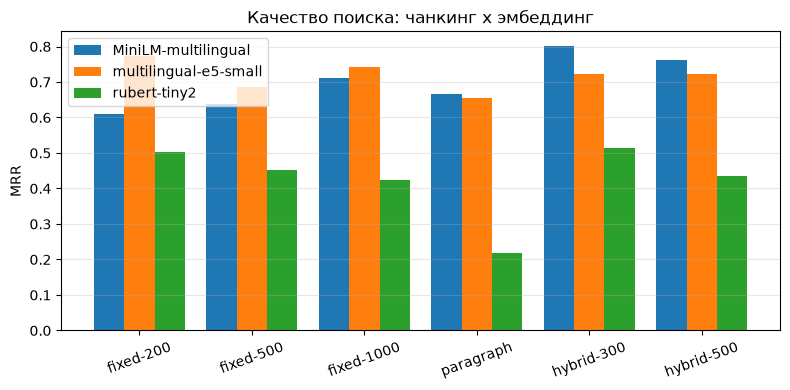

In [35]:
fig, ax = plt.subplots(figsize=(8, 4))
w = 0.27
for j, ek in enumerate(EMB):
    ax.bar(np.arange(len(CONFIGS)) + j * w, piv[ek].values, w, label=ek)
ax.set_xticks(np.arange(len(CONFIGS)) + w); ax.set_xticklabels(list(CONFIGS), rotation=20)
ax.set_ylabel("MRR"); ax.set_title("Качество поиска: чанкинг x эмбеддинг"); ax.legend(); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig("rag_grid.png", dpi=140); plt.show()

### 4.4. Влияние параметров чанкинга (размер чанка и перекрытие) для лучшей модели

Лучшая в среднем модель: multilingual-e5-small


,fixed,hybrid
размер,,
100,0.558,0.697
200,0.772,0.719
300,0.739,0.722
500,0.686,0.722
800,0.772,0.772
1200,0.761,0.772


,MRR fixed-300
"overlap, %",
0,0.691
10,0.739
25,0.728
50,0.707
75,0.700


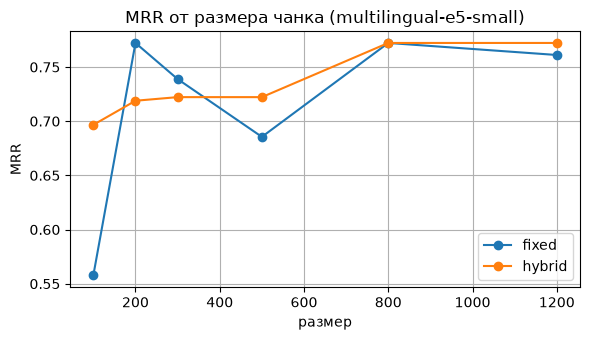

In [36]:
best_emb = piv.mean().idxmax(); print("Лучшая в среднем модель:", best_emb)
rows = []
for size in [100, 200, 300, 500, 800, 1200]:
    rows.append({"размер": size, "fixed": evaluate(add_metadata(fixed_chunks(paras, size, int(size*.1)), paras, DOCX_PATH), best_emb, f"sz{size}")["MRR"],
                 "hybrid": evaluate(add_metadata(hybrid_chunks(paras, size, int(size*.1), 60), paras, DOCX_PATH), best_emb, f"hz{size}")["MRR"]})
sweep = pd.DataFrame(rows).set_index("размер")
display(sweep.round(3))
ov = []
for o in [0, 10, 25, 50, 75]:
    ov.append({"overlap, %": o, "MRR fixed-300": evaluate(add_metadata(fixed_chunks(paras, 300, int(300*o/100)), paras, DOCX_PATH), best_emb, f"ov{o}")["MRR"]})
display(pd.DataFrame(ov).set_index("overlap, %").round(3))
sweep.plot(marker="o", figsize=(6, 3.5), title=f"MRR от размера чанка ({best_emb})", grid=True); plt.ylabel("MRR"); plt.tight_layout(); plt.savefig("rag_sweep.png", dpi=140); plt.show()

### 4.5. Фильтрация по метаданным (нативный API Chroma)

In [37]:
chunks_h = add_metadata(hybrid_chunks(paras, 300, 30, 60), paras, DOCX_PATH)
colh = build_collection(chunks_h, best_emb, "filters")
q = "Какие ограничения у лабораторного юзабилити-тестирования?"
def show(r, n=3):
    for d, m, dist in zip(r["documents"][0][:n], r["metadatas"][0][:n], r["distances"][0][:n]):
        print(f"  sim={1-dist:.3f} | chunk {m['chunk_index']:>2} | {m['chunk_type']:<16} | абзацы {m['para_start']}-{m['para_end']} | {m['section'][:38]!r} | {d[:70]}...")
print("Без фильтра:"); show(retrieve(colh, best_emb, q))
print("\nТолько split_paragraph (куски больших абзацев):"); show(retrieve(colh, best_emb, q, where={"chunk_type": "split_paragraph"}))
print("\nТолько раздел, начинающийся с «3 ОБЗОР МЕТОДА»  ($eq по полю section):")
secs = sorted({c["metadata"]["section"] for c in chunks_h}); print("  разделы:", [s[:30] for s in secs])
sec = next(s for s in secs if s.startswith("3 "))
show(retrieve(colh, best_emb, q, where={"section": sec}))
print("\nКомбинация условий ($and): раздел 4 И chunk_index > 20:")
sec4 = next(s for s in secs if s.startswith("4 "))
show(retrieve(colh, best_emb, q, where={"$and": [{"section": sec4}, {"chunk_index": {"$gt": 20}}]}))
print("\nwhere_document ($contains) — полнотекстовый фильтр по содержимому:")
r = colh.query(query_embeddings=[models[best_emb].encode(EMB[best_emb]["q"] + q, normalize_embeddings=True).tolist()], n_results=3, where_document={"$contains": "Выборка"}, include=["documents", "metadatas", "distances"]); show(r)
n_all = colh.count(); n_split = len(colh.get(where={"chunk_type": "split_paragraph"})["ids"])
print(f"\nВсего чанков {n_all}; из них split_paragraph {n_split}. Фильтр отрабатывает корректно: все найденные чанки удовлетворяют условию.")

Без фильтра:
  sim=0.886 | chunk 52 | split_paragraph  | абзацы 66-67 | '3 ОБЗОР МЕТОДА UX-ИССЛЕДОВАНИЯ «Анализ' | Преимущества метода. Лабораторное юзабилити-тестирование обладает рядо...
  sim=0.884 | chunk 30 | split_paragraph  | абзацы 54-55 | '3 ОБЗОР МЕТОДА UX-ИССЛЕДОВАНИЯ «Анализ' | Описание метода. Лабораторное юзабилити-тестирование — это качественны...
  sim=0.884 | chunk 34 | split_paragraph  | абзацы 56-57 | '3 ОБЗОР МЕТОДА UX-ИССЛЕДОВАНИЯ «Анализ' | Что именно фиксируется. В ходе лабораторного юзабилити-тестирования фи...

Только split_paragraph (куски больших абзацев):
  sim=0.886 | chunk 52 | split_paragraph  | абзацы 66-67 | '3 ОБЗОР МЕТОДА UX-ИССЛЕДОВАНИЯ «Анализ' | Преимущества метода. Лабораторное юзабилити-тестирование обладает рядо...
  sim=0.884 | chunk 30 | split_paragraph  | абзацы 54-55 | '3 ОБЗОР МЕТОДА UX-ИССЛЕДОВАНИЯ «Анализ' | Описание метода. Лабораторное юзабилити-тестирование — это качественны...
  sim=0.884 | chunk 34 | split_paragraph  | абзацы 56-57 |

### 4.6. ChromaDB через LlamaIndex
`ChromaVectorStore` оборачивает коллекцию, `VectorStoreIndex` строит индекс, `MetadataFilters` — тот же `where`, но в единой для всех хранилищ форме.
> Важно: по умолчанию LlamaIndex **добавляет метаданные в текст, который идёт в эмбеддинг и в LLM**. В исходных ноутбуках `excluded_embed_metadata_keys = []` означало «включать всё», поэтому в вектор попадали `author`, `source` и случайный `chunk_id`. Здесь служебные поля из эмбеддинга исключены.

In [38]:
from llama_index.core import VectorStoreIndex, StorageContext, Settings
from llama_index.core.schema import TextNode
from llama_index.vector_stores.chroma import ChromaVectorStore
from llama_index.embeddings.huggingface import HuggingFaceEmbedding
from llama_index.core.vector_stores import MetadataFilters, MetadataFilter, FilterOperator

Settings.embed_model = HuggingFaceEmbedding(model_name=EMB[best_emb]["name"],
                                            query_instruction=EMB[best_emb]["q"] or None, text_instruction=EMB[best_emb]["p"] or None)
Settings.llm = None                                      # пока без генерации

def to_nodes(chunks):
    nodes = []
    for c in chunks:
        n = TextNode(text=c["text"], metadata=c["metadata"], id_=c["metadata"]["chunk_id"])
        n.excluded_embed_metadata_keys = list(c["metadata"]); n.excluded_llm_metadata_keys = [k for k in c["metadata"] if k not in ("section",)]
        nodes.append(n)
    return nodes

def build_index(chunks, name):
    try: client.delete_collection(name)
    except Exception: pass
    vs = ChromaVectorStore(chroma_collection=client.get_or_create_collection(name, metadata={"hnsw:space": "cosine"}))
    return VectorStoreIndex(to_nodes(chunks), storage_context=StorageContext.from_defaults(vector_store=vs)), vs

index, vstore = build_index(chunks_h, "li-hybrid-300")
print("Узлов в Chroma:", client.get_collection("li-hybrid-300").count())
retr = index.as_retriever(similarity_top_k=3)
for nws in retr.retrieve(q):
    m = nws.node.metadata; print(f"  sim={nws.score:.3f} | chunk {m['chunk_index']} | {m['chunk_type']} | {nws.node.get_content()[:70]}...")
print("\nС MetadataFilters (chunk_type == split_paragraph):")
flt = MetadataFilters(filters=[MetadataFilter(key="chunk_type", value="split_paragraph", operator=FilterOperator.EQ)])
for nws in index.as_retriever(similarity_top_k=3, filters=flt).retrieve(q):
    m = nws.node.metadata; print(f"  sim={nws.score:.3f} | chunk {m['chunk_index']} | {m['chunk_type']} | {nws.node.get_content()[:70]}...")

modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/498k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/655 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

model.safetensors: downloading bytes:           |  0.00B            

... (5 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

LLM is explicitly disabled. Using MockLLM.
Узлов в Chroma: 74
  sim=0.893 | chunk 52 | split_paragraph | Преимущества метода. Лабораторное юзабилити-тестирование обладает рядо...
  sim=0.891 | chunk 30 | split_paragraph | Описание метода. Лабораторное юзабилити-тестирование — это качественны...
  sim=0.890 | chunk 34 | split_paragraph | Что именно фиксируется. В ходе лабораторного юзабилити-тестирования фи...

С MetadataFilters (chunk_type == split_paragraph):
  sim=0.893 | chunk 52 | split_paragraph | Преимущества метода. Лабораторное юзабилити-тестирование обладает рядо...
  sim=0.891 | chunk 30 | split_paragraph | Описание метода. Лабораторное юзабилити-тестирование — это качественны...
  sim=0.890 | chunk 34 | split_paragraph | Что именно фиксируется. В ходе лабораторного юзабилити-тестирования фи...


In [39]:
# Проверка на дубли (баг исходных ноутбуков): повторный запуск не должен увеличивать число записей
c1 = client.get_collection("li-hybrid-300").count()
index, vstore = build_index(chunks_h, "li-hybrid-300")
c2 = client.get_collection("li-hybrid-300").count()
print(f"после первого запуска: {c1}, после повторного: {c2} ->", "дублей нет" if c1 == c2 else "ДУБЛИ!")

после первого запуска: 74, после повторного: 74 -> дублей нет


## 5. Лёгкая LLM (Ollama) через LlamaIndex
Модель `llama3.2:3b`. Промпт требует отвечать строго по контексту и отказываться, если ответа в контексте нет. Ответ оцениваем автоматически: содержит ли он ключевое слово из эталона (для вопроса вне документа — содержит ли он фразу отказа).

In [40]:
import requests
try:
    tags = requests.get(OLLAMA_URL + "/api/tags", timeout=5).json()
    print("Ollama работает, модели:", [m["name"] for m in tags["models"]])
    OLLAMA_OK = True
except Exception as e:
    print("Ollama недоступна:", e); OLLAMA_OK = False

Ollama работает, модели: ['bge-m3:latest', 'qwen2.5:7b', 'llama3.2:3b']


In [41]:
from llama_index.llms.ollama import Ollama
from llama_index.core.prompts import PromptTemplate
REFUSAL = "К сожалению, в предоставленном документе нет информации об этом."
QA_PROMPT = PromptTemplate(
    "Контекст из документа:\n---------------------\n{context_str}\n---------------------\n"
    "Отвечай на вопрос СТРОГО на основе контекста выше, не используя посторонних знаний.\n"
    "Если в контексте нет ответа, ответь ровно фразой: '" + REFUSAL + "'\n"
    "Отвечай кратко, по-русски.\n\nВопрос: {query_str}\nОтвет:")
if OLLAMA_OK:
    llm = Ollama(model="llama3.2:3b", base_url=OLLAMA_URL, request_timeout=600.0, temperature=0.0, context_window=4096)
    Settings.llm = llm
    print(llm.complete("Скажи 'ок' одним словом.").text)

'Ок'.


### 5.1. Зависимость ответа от чанкинга и эмбеддинга
Берём ту же выборку вопросов и сравниваем три конфигурации: плохую (fixed-200), среднюю и лучшую по MRR.

In [42]:
def run_generation(chunks, emb_key, tag, questions, top_k=3):
    Settings.embed_model = HuggingFaceEmbedding(model_name=EMB[emb_key]["name"], query_instruction=EMB[emb_key]["q"] or None, text_instruction=EMB[emb_key]["p"] or None)
    idx, _ = build_index(chunks, f"gen-{tag}")
    qe = idx.as_query_engine(similarity_top_k=top_k, text_qa_template=QA_PROMPT, llm=llm)
    out = []
    for q_, kw in questions:
        t = time.time(); r = qe.query(q_)
        ans = r.response.strip()
        ok = (REFUSAL[:25].lower() in ans.lower()) if kw is None else (kw.lower() in ans.lower())
        out.append(dict(вопрос=q_[:55], ответ=ans.replace("\n", " ")[:160], верно=ok, сек=round(time.time() - t, 1),
                        чанки=[n.node.metadata["chunk_index"] for n in r.source_nodes]))
    return pd.DataFrame(out)

In [43]:
gen_sets = [(q_, kw) for q_, _, kw in QA[:8]] + [(OOS, None)]
best_cfg = grid.groupby("чанкинг")["MRR"].mean().idxmax(); worst_cfg = grid.groupby("чанкинг")["MRR"].mean().idxmin()
print("Лучший чанкинг по среднему MRR:", best_cfg, "| худший:", worst_cfg)
gen_results = {}
if OLLAMA_OK:
    for cfg_name, emb in [(worst_cfg, "MiniLM-multilingual"), (best_cfg, "MiniLM-multilingual"), (best_cfg, best_emb)]:
        t = time.time()
        gen_results[(cfg_name, emb)] = run_generation(CONFIGS[cfg_name](), emb, f"{cfg_name}-{emb}"[:40], gen_sets)
        print(f"{cfg_name:<12}{emb:<22} верных ответов {gen_results[(cfg_name, emb)]['верно'].sum()}/{len(gen_sets)}  ({time.time()-t:.0f} с)")

Лучший чанкинг по среднему MRR: hybrid-300 | худший: paragraph


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

paragraph   MiniLM-multilingual    верных ответов 8/9  (19 с)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

hybrid-300  MiniLM-multilingual    верных ответов 5/9  (16 с)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

hybrid-300  multilingual-e5-small  верных ответов 6/9  (16 с)


In [44]:
if gen_results:
    summary = pd.DataFrame({f"{c} + {e}": r["верно"].values for (c, e), r in gen_results.items()}, index=[g[0][:50] for g in gen_sets])
    display(summary.replace({True: "да", False: "нет"}))
    k0 = list(gen_results)[-1]; display(gen_results[k0][["вопрос", "ответ", "чанки", "сек"]])

,paragraph + MiniLM-multilingual,hybrid-300 + MiniLM-multilingual,hybrid-300 + multilingual-e5-small
В каком году компания Game Stream получила статус,да,нет,да
Какой юридический адрес у ООО «Гейм Стрим»?,да,да,нет
Какой технологический стек используется в компании,да,да,да
Какие ограничения у лабораторного юзабилити-тестир,да,нет,нет
Из каких этапов состоит лабораторное тестирование?,да,да,да
Какой пример юзабилити-теста связан с интернет-бан,да,да,нет
Какие боли испытывают покупатели 5element.by?,да,нет,да
Кто является центральным персонажем карты эмпатии?,нет,нет,да
Дай мне рецепт пиццы Маргарита,да,да,да


,вопрос,ответ,чанки,сек
0,В каком году компания Game Stream получила статус резид,В 2008 году.,"[14, 15, 13]",0.6
1,Какой юридический адрес у ООО «Гейм Стрим»?,"К сожалению, в предоставленном документе нет информации об юридическом адрес...","[11, 26, 18]",0.9
2,Какой технологический стек используется в компании?,"В компании ООО «Гейм Стрим» используются технологии: C#, C++, Python, Go, Ja...","[25, 24, 70]",1.6
3,Какие ограничения у лабораторного юзабилити-тестировани,"К сожалению, в предоставленном документе нет информации об этом.","[52, 30, 34]",0.8
4,Из каких этапов состоит лабораторное тестирование?,Лабораторное тестирование состоит из следующих этапов: 1. Формирование сцен...,"[37, 31, 30]",1.3
5,Какой пример юзабилити-теста связан с интернет-банком?,"К сожалению, в предоставленном документе нет информации об этом.","[30, 52, 34]",0.8
6,Какие боли испытывают покупатели 5element.by?,Покупатели 5element.by испытывают следующие боли: сложные или перегруженные ...,"[59, 61, 71]",2.2
7,Кто является центральным персонажем карты эмпатии?,Иван Будько.,"[62, 4, 9]",0.6
8,Дай мне рецепт пиццы Маргарита,"К сожалению, в предоставленном документе нет информации об этом.","[6, 2, 29]",0.6


## 6. Полный RAG-пайплайн
Чтение документов → чанкинг → эмбеддинги и метаданные → загрузка в векторную БД и поиск → генерация ответа LLM.
Весь пайплайн собран в одну функцию-класс, параметры чанкинга, модель эмбеддингов и фильтры меняются аргументами.

In [45]:
class RagPipeline:
    def __init__(self, docx_path, emb_key="multilingual-e5-small", max_chars=300, overlap=30, min_chars=60, top_k=3, collection="rag-final"):
        self.top_k, self.emb_key = top_k, emb_key
        # 1) чтение документа
        d = Document(docx_path)
        self.paras = [{"idx_in_docx": i, "style": p.style.name, "text": p.text.replace("\xa0", " ").strip()} for i, p in enumerate(d.paragraphs) if p.text.strip()]
        # 2) чанкинг + 3) метаданные
        self.chunks = add_metadata(hybrid_chunks(self.paras, max_chars, overlap, min_chars), self.paras, docx_path)
        # 4) эмбеддинги + загрузка в Chroma (через LlamaIndex)
        Settings.embed_model = HuggingFaceEmbedding(model_name=EMB[emb_key]["name"], query_instruction=EMB[emb_key]["q"] or None, text_instruction=EMB[emb_key]["p"] or None)
        self.index, _ = build_index(self.chunks, collection)
    def search(self, question, where=None):
        filters = None if not where else MetadataFilters(filters=[MetadataFilter(key=k, value=v) for k, v in where.items()])
        return self.index.as_retriever(similarity_top_k=self.top_k, filters=filters).retrieve(question)
    def answer(self, question, where=None):
        nodes = self.search(question, where)
        ctx = "\n\n".join(n.node.get_content() for n in nodes)
        # 5) генерация
        text = Settings.llm.complete(QA_PROMPT.format(context_str=ctx, query_str=question)).text.strip() if OLLAMA_OK else "(Ollama не запущена: покажем только найденный контекст)"
        return text, nodes

rag = RagPipeline(DOCX_PATH)
print(f"Пайплайн готов: {len(rag.paras)} абзацев -> {len(rag.chunks)} чанков -> Chroma '{'rag-final'}'")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Пайплайн готов: 83 абзацев -> 74 чанков -> Chroma 'rag-final'


In [46]:
demo_q = ["Кто центральный персонаж карты эмпатии для 5element.by?", "Какие этапы включает лабораторное юзабилити-тестирование?", OOS]
for question in demo_q:
    t = time.time(); ans, nodes = rag.answer(question)
    print(f"\n❓ {question}\n💬 {ans}")
    print("   источники:", [(n.node.metadata["chunk_id"], n.node.metadata["chunk_type"], round(n.score, 3)) for n in nodes], f"[{time.time()-t:.0f} с]")


❓ Кто центральный персонаж карты эмпатии для 5element.by?
💬 Иван Будько.
   источники: [('a42ed8e7_0004', 'full_paragraph', 0.874), ('a42ed8e7_0062', 'full_paragraph', 0.868), ('a42ed8e7_0058', 'full_paragraph', 0.866)] [0 с]

❓ Какие этапы включает лабораторное юзабилити-тестирование?
💬 К сожалению, в предоставленном документе нет информации об этом.
   источники: [('a42ed8e7_0030', 'split_paragraph', 0.919), ('a42ed8e7_0034', 'split_paragraph', 0.903), ('a42ed8e7_0052', 'split_paragraph', 0.895)] [1 с]

❓ Дай мне рецепт пиццы Маргарита
💬 К сожалению, в предоставленном документе нет информации об этом.
   источники: [('a42ed8e7_0006', 'merged_paragraphs', 0.826), ('a42ed8e7_0002', 'merged_paragraphs', 0.825), ('a42ed8e7_0029', 'full_paragraph', 0.818)] [1 с]
